# Math 50 HW2
## Jack Chou


### Load Data

In [12]:
# Loads the Gaza and Ukraine casualty datasets for Math 50 Assignment 2
# into dataframes `gaza` and `ukraine`. Data is loaded directly from
# math50-data (raw GitHub URLs), so this notebook runs as-is in Colab.

# Load Script Source: Ethan Levien

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [13]:
GAZA_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/gaza-casualties.csv"
UKRAINE_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/ukraine-personnel-losses.csv"

BURN = 300  # drop the first 300 days: low, volatile early counts
GAZA_CEASEFIRE = pd.Timestamp("2025-10-10")


def load_gaza():
    # columns: time, counts (cumulative), daily (day-over-day increment),
    # period ("before"/"after" the ceasefire, in place of truncating),
    # plus a few of the other reported sub-counts
    df = pd.read_csv(GAZA_URL, parse_dates=["report_date"])
    counts = df["ext_killed_cum"].to_numpy().astype(float)
    daily = np.empty(len(counts))
    daily[0] = np.nan
    daily[1:] = counts[1:] - counts[:-1]

    period = np.empty(len(df), dtype=object)
    before = (df["report_date"] <= GAZA_CEASEFIRE).to_numpy()
    period[before] = "before"
    period[~before] = "after"

    out = pd.DataFrame({
        "time": df["report_date"],
        "counts": counts,
        "daily": daily,
        "period": period,
        "children_killed_cum": df["ext_killed_children_cum"].to_numpy(),
        "women_killed_cum": df["ext_killed_women_cum"].to_numpy(),
        "injured_cum": df["ext_injured_cum"].to_numpy(),
    })
    return out.iloc[BURN + 1:].reset_index(drop=True)


def load_ukraine():
    # columns: time, counts (cumulative), daily (day-over-day increment), POW
    df = pd.read_csv(UKRAINE_URL, parse_dates=["date"])
    counts = df["personnel"].to_numpy().astype(float)
    daily = np.empty(len(counts))
    daily[0] = np.nan
    daily[1:] = counts[1:] - counts[:-1]

    out = pd.DataFrame({
        "time": df["date"],
        "counts": counts,
        "daily": daily,
        "POW": df["POW"].to_numpy(),
    })
    return out.iloc[BURN + 1:].reset_index(drop=True)


gaza = load_gaza()
ukraine = load_ukraine()
gaza

,time,counts,daily,period,children_killed_cum,women_killed_cum,injured_cum
0,2024-08-03,39550.0,31.0,before,16314,10980,91280
1,2024-08-04,39583.0,33.0,before,16314,10980,91398
2,2024-08-05,39623.0,40.0,before,16314,10980,91469
3,2024-08-06,39653.0,30.0,before,16365,11012,91535
4,2024-08-07,39677.0,24.0,before,16365,11012,91645
...,...,...,...,...,...,...,...
776,2026-09-18,73821.0,0.0,after,20179,12500,174897
777,2026-09-19,73910.0,89.0,after,20179,12500,174914
778,2026-09-20,73910.0,0.0,after,20179,12500,174935
779,2026-09-21,73914.0,4.0,after,20179,12500,174952


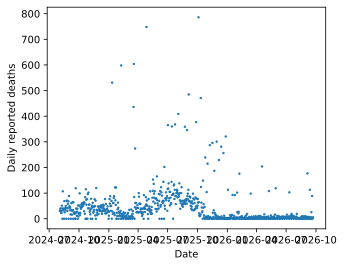

In [14]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(gaza.time, gaza.daily, ".", markersize=3)
ax.set_xlabel("Date")
ax.set_ylabel("Daily reported deaths")
plt.show()

In [15]:
ukraine

,time,counts,daily,POW
0,2022-12-23,100950.0,550.0,NaN
1,2022-12-24,101430.0,480.0,NaN
2,2022-12-25,102050.0,620.0,NaN
3,2022-12-26,102600.0,550.0,NaN
4,2022-12-27,103220.0,620.0,NaN
...,...,...,...,...
1365,2026-09-18,1514910.0,1420.0,NaN
1366,2026-09-19,1516430.0,1520.0,NaN
1367,2026-09-20,1517990.0,1560.0,NaN
1368,2026-09-21,1519650.0,1660.0,NaN


## Problem 1: Parsing Wyner's Argument

### 1.1 Wyner's two main observations

1. The daily totals are too regular. Wyner writes that "the daily reported casualty count over this period averages 270 plus or minus about 15%" and that "there should be days with twice the average or more and others with half or less." He also says the graph of total deaths is "increasing with almost metronomical linearity" (Figure 1).
2. The breakdown by group does not behave like real data. Women and children counts are not correlated: "R2 is .017 which is statistically and substantively not different from 0." Men and women are strongly negatively correlated: "there is a strong negative correlation, which makes no sense at all."

From these he concludes that "a process unconnected or loosely connected to reality was used to report the numbers." He adds some smaller anomalies, such as the Oct. 28 to Oct. 29 reports implying that "26 men came back to life."

In [16]:
# Helper functions
rng = np.random.default_rng(42)


# R^2 of a simple linear regression of y on x, squared correlation coefficient
def r2(x, y):
    return np.corrcoef(x, y)[0, 1] ** 2

# coefficient of variation: standard deviation divided by the mean
def cv(x):
    return np.std(x, ddof=1) / np.mean(x)

# returns SS_res and SS_tot for the regression of y on x
def ss_parts(x, y):
    slope, intercept = np.polyfit(x, y, 1)
    resid = y - (slope * x + intercept)
    ss_res = np.sum(resid ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return ss_res, ss_tot

The first block rebuilds Wyner's own window from the raw data. The numbers are close to his but not identical (his are CV about 15% and R2 of .017). The source here is the Tech for Palestine compilation and he used a different one.

In [17]:
# The loader above drops the first 300 days, so Wyner's window is not in the `gaza` dataframe
# Read the raw file again and keep Oct 26 to Nov 10, 2023.
raw = pd.read_csv(GAZA_URL, parse_dates=["report_date"])
win = raw[(raw.report_date >= "2023-10-26") & (raw.report_date <= "2023-11-10")]

# 16 cumulative reports give 15 daily increments
N = np.diff(win.ext_killed_cum.to_numpy().astype(float))           # everyone
C = np.diff(win.ext_killed_children_cum.to_numpy().astype(float))  # children
F = np.diff(win.ext_killed_women_cum.to_numpy().astype(float))     # women
M = N - C - F                                                      # men, as Wyner defines it
day = np.arange(len(N))

print("days:", len(N))
print("mean daily total:", N.mean().round(1))
print("sd of daily total:", N.std(ddof=1).round(1))
print("CV of daily total:", cv(N).round(3))
print("R2 of cumulative total vs day:", r2(day, np.cumsum(N)).round(3))
print("R2 of daily total vs day:", r2(day, N).round(3))
print("R2 of women vs children:", r2(F, C).round(3))
print("corr of men vs women:", np.corrcoef(M, F)[0, 1].round(3))

days: 15
mean daily total: 270.0
sd of daily total: 44.8
CV of daily total: 0.166
R2 of cumulative total vs day: 0.998
R2 of daily total vs day: 0.196
R2 of women vs children: 0.012
corr of men vs women: -0.38


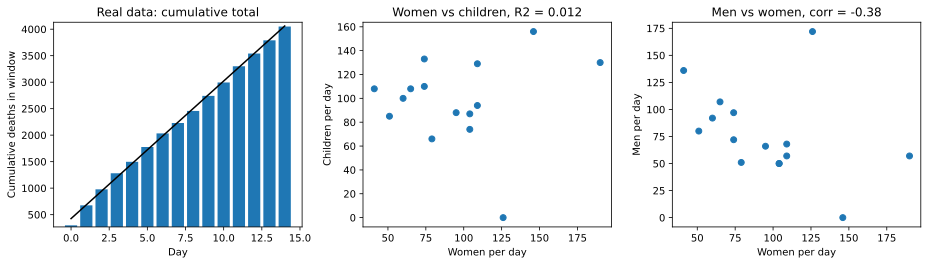

In [18]:
# Remake Wyner's Figure 1 (cumulative total with a line) and the two scatter plots
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))

cum = np.cumsum(N)
slope, intercept = np.polyfit(day, cum, 1)
ax[0].bar(day, cum, color="C0")
ax[0].plot(day, slope * day + intercept, "k-")
ax[0].set_ylim(cum.min() * 0.9, cum.max() * 1.02)  # zoom in like Wyner did
ax[0].set_title("Real data: cumulative total")
ax[0].set_xlabel("Day")
ax[0].set_ylabel("Cumulative deaths in window")

ax[1].plot(F, C, "o")
ax[1].set_title(f"Women vs children, R2 = {r2(F, C):.3f}")
ax[1].set_xlabel("Women per day")
ax[1].set_ylabel("Children per day")

ax[2].plot(F, M, "o")
ax[2].set_title(f"Men vs women, corr = {np.corrcoef(M, F)[0, 1]:.2f}")
ax[2].set_xlabel("Women per day")
ax[2].set_ylabel("Men per day")

plt.tight_layout()
plt.show()

### 1.2 Wyner's observations as probability statements

Let $N_i = M_i + F_i + C_i$ be the total on day $i$, where $M_i$ is men, $F_i$ is women and $C_i$ is children.

1. Low variation. "270 plus or minus about 15%" means $SD(N_i)/E[N_i] \approx 0.15$. So $P(N_i \ge 2E[N_i])$ and $P(N_i \le E[N_i]/2)$ are close to 0. Wyner thinks both should be clearly positive for real data.
2. No correlation between women and children. "R2 is .017" means $Corr(F_i, C_i)^2 \approx 0.017$. Wyner thinks $Corr(F_i, C_i)$ should be clearly positive, because the same strikes drive both counts.
3. Men has a negative correlation against women "A strong negative correlation" means $Corr(M_i, F_i) < 0$. Wyner thinks it should be positive for the same reason as listed in the 2nd point.

His final story also gives a fourth statement. About 70% of the total goes to women and children, so $E[(F_i + C_i)/N_i] \approx 0.7$, with a random split between $F_i$ and $C_i$ and men filling in the rest.

The simulation below follows that story. Then I remake his plots.

**Assumptions and modeling choices.**

- Daily totals are Normal(270, 42), so the CV is about .15. I clip at 0 and use real numbers instead of counts.
- Days are independent, with no trend or weekly cycle.
- The share of women is Uniform(0.15, 0.50) and the share of children is Uniform(0.20, 0.55), independent of each other and of the total. Together they average about 70%. Men are the remainder.
- 15 days, fixed random seed.

The split rule matters. Dividing a fixed 70% between women and children would force a negative correlation between them, so I used independent shares, the simplest choice with no built-in link.

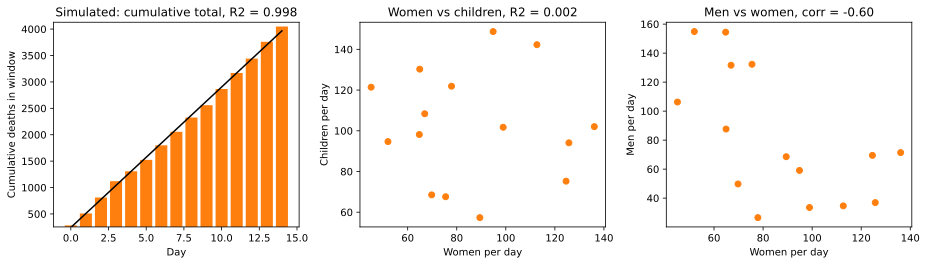

,mean,5%,95%
CV of daily total,0.153,0.107,0.205
R2 cumulative vs day,0.999,0.997,1.000
R2 women vs children,0.112,0.001,0.386
corr men vs women,-0.459,-0.753,-0.086


In [19]:
def simulate_wyner(n=15, mean=270, sd=42):
    N_sim = np.clip(rng.normal(mean, sd, n), 0, None)  # daily totals, real numbers
    a = rng.uniform(0.15, 0.50, n)                      # share that are women
    b = rng.uniform(0.20, 0.55, n)                      # share that are children
    F_sim = N_sim * a
    C_sim = N_sim * b
    M_sim = N_sim - F_sim - C_sim                       # men fill in the rest
    return N_sim, F_sim, C_sim, M_sim


N_s, F_s, C_s, M_s = simulate_wyner()
d_s = np.arange(15)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
cum_s = np.cumsum(N_s)
slope, intercept = np.polyfit(d_s, cum_s, 1)
ax[0].bar(d_s, cum_s, color="C1")
ax[0].plot(d_s, slope * d_s + intercept, "k-")
ax[0].set_ylim(cum_s.min() * 0.9, cum_s.max() * 1.02)
ax[0].set_title(f"Simulated: cumulative total, R2 = {r2(d_s, cum_s):.3f}")
ax[0].set_xlabel("Day")
ax[0].set_ylabel("Cumulative deaths in window")

ax[1].plot(F_s, C_s, "o", color="C1")
ax[1].set_title(f"Women vs children, R2 = {r2(F_s, C_s):.3f}")
ax[1].set_xlabel("Women per day")
ax[1].set_ylabel("Children per day")

ax[2].plot(F_s, M_s, "o", color="C1")
ax[2].set_title(f"Men vs women, corr = {np.corrcoef(M_s, F_s)[0, 1]:.2f}")
ax[2].set_xlabel("Women per day")
ax[2].set_ylabel("Men per day")

plt.tight_layout()
plt.show()

# One draw can be unlucky, so repeat 2000 times and look at the spread
out = []
for _ in range(2000):
    n_, f_, c_, m_ = simulate_wyner()
    out.append([cv(n_), r2(d_s, np.cumsum(n_)), r2(f_, c_), np.corrcoef(m_, f_)[0, 1]])
out = np.array(out)
summary = pd.DataFrame(
    {"mean": out.mean(0), "5%": np.percentile(out, 5, axis=0), "95%": np.percentile(out, 95, axis=0)},
    index=["CV of daily total", "R2 cumulative vs day", "R2 women vs children", "corr men vs women"],
)
summary.round(3)

The simulated data reproduce all of Wyner's patterns. Over 2000 repeats the cumulative R2 is almost always above .99, the CV is near .15 and the men vs women correlation is negative. The women vs children R2 is not always tiny but values near 0 are common (see the 5% column).

## Problem 2: Regression on Cumulative vs Daily Deaths

### 2.1 Why a cumulative process correlates strongly with time

$R^2 = 1 - SS_{R}/SS_{tot}$, where $SS_R$ is the sum of squared residuals and $SS_{tot}$ is the total variation of the response.

A cumulative sum $y_i = x_1 + \dots + x_i$ climbs by about the mean $\mu$ each day. So $y_i$ is spread over a range of about $\mu n$ and $SS_{tot} \approx \mu^2 n^3 / 12$. The residuals only contain the leftover noise, which is about the same size as the noise in the daily counts. So $SS_R$ does not grow nearly as fast and $SS_R / SS_{tot}$ is tiny. Any count series with a positive mean gets $R^2$ close to 1 after it is accumulated. This says nothing about whether the numbers are real.

The code below shows this for Wyner's window. $SS_R$ is the same order for both series but $SS_{tot}$ is huge for the cumulative one.

In [20]:
# SS_res and SS_tot for daily counts vs cumulative counts
# Use the real Wyner window first
for name, y in [("daily total x_i", N), ("cumulative total y_i", np.cumsum(N))]:
    ss_res, ss_tot = ss_parts(day, y)
    print(f"{name:22s} SS_res = {ss_res:12.0f}   SS_tot = {ss_tot:12.0f}   R2 = {1 - ss_res / ss_tot:.3f}")

daily total x_i        SS_res =        22592   SS_tot =        28092   R2 = 0.196
cumulative total y_i   SS_res =        33686   SS_tot =     18907125   R2 = 0.998


In [21]:
# Now use simulated data with the same mean (270) and growing variance
# Pachter's point is that even a ten-fold bigger variance still gives a very high R2
rows = []
for var in [0, 42 ** 2, 270, 1785, 17850]:
    r2_daily, r2_cum = [], []
    ssr_cum, sst_cum = [], []
    for _ in range(1000):
        x = np.clip(rng.normal(270, np.sqrt(var), 15), 0, None)
        r2_daily.append(r2(day, x) if var > 0 else 0.0)
        r2_cum.append(r2(day, np.cumsum(x)))
        a, b = ss_parts(day, np.cumsum(x))
        ssr_cum.append(a)
        sst_cum.append(b)
    rows.append([var, np.mean(r2_daily), np.mean(r2_cum), np.mean(ssr_cum), np.mean(sst_cum)])

pd.DataFrame(rows, columns=["daily variance", "mean R2 daily", "mean R2 cumulative",
                            "mean SS_res (cum)", "mean SS_tot (cum)"]).round(3)

,daily variance,mean R2 daily,mean R2 cumulative,mean SS_res (cum),mean SS_tot (cum)
0,0,0.000,1.000,0.000,2.041200e+07
1,1764,0.071,0.999,26419.341,2.054203e+07
2,270,0.068,1.000,3902.826,2.042518e+07
3,1785,0.069,0.999,25523.805,2.048594e+07
4,17850,0.074,0.987,255462.674,2.131651e+07


Pachter's point holds. Even when the daily variance is ten times larger than Wyner's, the cumulative $R^2$ stays near .99. The daily $R^2$ stays small because the daily counts have no trend. A large cumulative $R^2$ is what we expect from almost any count data.

### 2.2 The Pachter comment and the Gelman rule for good science

Pachter writes that "when one starts floating tons of hypotheses, especially with little data, evidence for one of them doesn't carry significance." This is the **garden of forking paths** (researcher degrees of freedom) from the Gelman post "7 steps to junk science." If you may look for any anomaly, you will find one. A single surprising pattern is then weak evidence. His example is that a mean of exactly 270 happens about 7% of the time. That is a surprise only because we noticed it after the fact.

I mostly agree that it applies here, for three reasons.

- Wyner looked at one window of 15 days. Commenters say nearby dates give less regular numbers. The window choice is a forking path.
- He ran several tests (CV, women vs children, men vs women, the "men came back to life" day). None were adjusted for multiple comparisons.
- He admits "verified control data is not available." So there was no baseline for what regular means.

The rule does not show that the numbers are real. It only says that this evidence is weak. Not being able to prove fabrication is different from showing the data are fine.

### 2.3 "Not the abundance of anomalies but their inherent contradictions"

The commenter has a fair point. If the numbers came from one clean process, then women, children and men should all move together. Finding no link or a negative link looks contradictory.

But these contradictions only hold if all three counts are measured the same way on the same day. Other explanations are plausible.

- **Different clocks.** Commenters point out that totals come from the Ministry and the women and children counts from the Media Office, at different times of day.
- **Batching.** Identifying women and children needs name records, so these counts may be updated in bunches. Totals are updated daily.
- **Men are a leftover.** $M_i = N_i - F_i - C_i$. If women are not updated on a day, men look high. When women are updated in a big batch, men look low. This creates a negative correlation by construction.
- **Small samples.** With only 15 days the correlation estimates are very noisy (see the 5% to 95% range above).
- **Chaos.** Reporting in the north stopped in November, in the middle of Wyner's window.

The simulation below tests the first three ideas. The truth is built so that women, children and men all move together. Then women and children are reported in batches.

In [22]:
# Can reporting lags create "contradictions" in a REAL process?
# Bad days are bad for everyone, so women, children and men move together
def true_process(n=15):
    lam = rng.gamma(shape=6, scale=270 / 6, size=n) # daily intensity varies a lot
    N_t = rng.poisson(lam) # total deaths
    F_t = rng.binomial(N_t, 0.33) # women
    C_t = rng.binomial(N_t, 0.34) # children
    return N_t.astype(float), F_t.astype(float), C_t.astype(float)

# Each day the cumulative count is updated only with probability p
# If it is not updated, the old cumulative value is repeated
def batch_report(x, p=0.5):
    cum = np.cumsum(x)
    rep = np.zeros_like(cum)
    last = 0.0
    for i in range(len(cum)):
        if rng.random() < p or i == len(cum) - 1:
            last = cum[i]
        rep[i] = last
    return np.diff(np.concatenate([[0.0], rep]))


no_lag, lag = [], []
for _ in range(2000):
    N_t, F_t, C_t = true_process()
    M_t = N_t - F_t - C_t
    no_lag.append([r2(F_t, C_t), np.corrcoef(M_t, F_t)[0, 1]])

    # total is reported daily but women and children are reported in batches
    F_r = batch_report(F_t)
    C_r = batch_report(C_t)
    M_r = N_t - F_r - C_r     # men as a leftover
    lag.append([r2(F_r, C_r), np.corrcoef(M_r, F_r)[0, 1]])

pd.DataFrame(
    {"no lag": np.mean(no_lag, axis=0), "with batching": np.mean(lag, axis=0)},
    index=["R2 women vs children", "corr men vs women"],
).round(3)

,no lag,with batching
R2 women vs children,0.911,0.099
corr men vs women,0.887,-0.577


Without lags, women and children are strongly correlated and men move with women. With batching the same real process gives a women vs children R2 near .1 and a negative men vs women correlation. These match Wyner's "contradictions." This does not prove that batching happened. It shows that the patterns Wyner found do not need fabrication to occur.

## Problem 3: Examining Real Data

### 3.1 Random windows with the same length as Wyner's

Wyner used 15 days. I sample many random 15-day windows and compute the CV and the cumulative $R^2$ for each. The Gaza data has three parts. The first 300 days (which the loader drops), the later war period before the ceasefire, and the period after the ceasefire. I use the first two and Ukraine.

Gaza (before) days: 434  Ukraine days: 1370


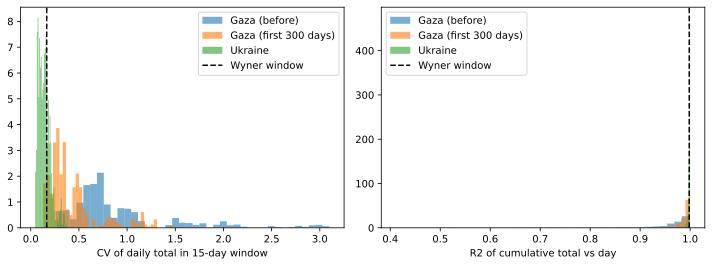

,Gaza (first 300 days),Gaza (before),Ukraine
median CV,0.334,0.714,0.136
share of windows with CV <= Wyner's,0.066,0.000,0.718
median R2 (cumulative),0.993,0.975,0.999
share with R2 >= Wyner's,0.086,0.000,0.650


In [23]:
# Only the "before ceasefire" part of Gaza is used, to match Wyner's war-time setting.
gaza_before = gaza[gaza.period == "before"].reset_index(drop=True)
print("Gaza (before) days:", len(gaza_before), " Ukraine days:", len(ukraine))


def window_stats(daily, n_windows=2000, length=15):
    # pick random start days, then compute CV and cumulative R2 for each window
    daily = np.asarray(daily, dtype=float)
    starts = rng.integers(0, len(daily) - length, n_windows)
    t = np.arange(length)
    cvs, r2s = [], []
    for s in starts:
        x = daily[s:s + length]
        cvs.append(cv(x))
        r2s.append(r2(t, np.cumsum(x)))
    return np.array(cvs), np.array(r2s)


# The first 300 days were dropped by the loader, so rebuild them from the raw file.
early = raw.iloc[:301]
early_daily = np.diff(early.ext_killed_cum.to_numpy().astype(float))

cv_g, r2_g = window_stats(gaza_before.daily)
cv_e, r2_e = window_stats(early_daily)
cv_u, r2_u = window_stats(ukraine.daily)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(cv_g, bins=40, alpha=0.6, label="Gaza (before)", density=True)
ax[0].hist(cv_e, bins=40, alpha=0.6, label="Gaza (first 300 days)", density=True)
ax[0].hist(cv_u, bins=40, alpha=0.6, label="Ukraine", density=True)
ax[0].axvline(cv(N), color="k", ls="--", label="Wyner window")
ax[0].set_xlabel("CV of daily total in 15-day window")
ax[0].legend()
ax[1].hist(r2_g, bins=40, alpha=0.6, label="Gaza (before)", density=True)
ax[1].hist(r2_e, bins=40, alpha=0.6, label="Gaza (first 300 days)", density=True)
ax[1].hist(r2_u, bins=40, alpha=0.6, label="Ukraine", density=True)
ax[1].axvline(r2(day, np.cumsum(N)), color="k", ls="--", label="Wyner window")
ax[1].set_xlabel("R2 of cumulative total vs day")
ax[1].legend()
plt.tight_layout()
plt.show()

def row(c, r):
    # four summary numbers for one series of windows
    return [np.median(c), np.mean(c <= cv(N)), np.median(r), np.mean(r >= r2(day, np.cumsum(N)))]


table = pd.DataFrame({
    "Gaza (first 300 days)": row(cv_e, r2_e),
    "Gaza (before)": row(cv_g, r2_g),
    "Ukraine": row(cv_u, r2_u),
}, index=["median CV", "share of windows with CV <= Wyner's", "median R2 (cumulative)", "share with R2 >= Wyner's"])
table.round(3)

**Results.**

- In the first 300 days of the Gaza data, about 5% of windows are as regular as Wyner's (CV at or below his). So his window is on the regular end but it is not impossible.
- In the later war period (before the ceasefire) no window is that regular. The median CV is above .7 and some days are 0. The numbers come in lumps (weekly updates and corrections).
- Ukraine windows are *more* regular than Wyner's. The median CV is about .13 and most windows have CV below his.

So the answer is no. Random Gaza windows do not usually give Wyner's result. But the same low CV and high cumulative $R^2$ appear in a data set nobody calls fake.

Next I check the women vs children result. After the burn-in these columns change on only about 5% of days, so I use the first 300 days.

In [24]:
# Women vs children needs the breakdown columns.
# After the burn-in these are updated rarely, so check how often they change.
sub = gaza_before.copy()
for col in ["women_killed_cum", "children_killed_cum"]:
    changed = np.diff(sub[col].to_numpy()) != 0
    print(f"{col}: changes on {changed.mean():.0%} of days after the burn-in")

for col in ["ext_killed_women_cum", "ext_killed_children_cum"]:
    changed = np.diff(early[col].to_numpy()) != 0
    print(f"{col}: changes on {changed.mean():.0%} of days in the first 300 days")

women_killed_cum: changes on 5% of days after the burn-in
children_killed_cum: changes on 6% of days after the burn-in
ext_killed_women_cum: changes on 33% of days in the first 300 days
ext_killed_children_cum: changes on 34% of days in the first 300 days


In [25]:
# Women vs children R2 over random 15-day windows of the first 300 days.
# Many windows have days with no update, so these R2 values are rough.
Fe = np.diff(early.ext_killed_women_cum.to_numpy().astype(float))
Ce = np.diff(early.ext_killed_children_cum.to_numpy().astype(float))
Ne = np.diff(early.ext_killed_cum.to_numpy().astype(float))
Me = Ne - Fe - Ce

vals = []
for s in rng.integers(0, len(Fe) - 15, 2000):
    f, c, m = Fe[s:s + 15], Ce[s:s + 15], Me[s:s + 15]
    if f.std() > 0 and c.std() > 0 and m.std() > 0:
        vals.append([r2(f, c), np.corrcoef(m, f)[0, 1]])
vals = np.array(vals)
print("windows used:", len(vals))
print("median R2 women vs children:", np.median(vals[:, 0]).round(3))
print("share with R2 <= 0.017:", np.mean(vals[:, 0] <= 0.017).round(3))
print("median corr men vs women:", np.median(vals[:, 1]).round(3))
print("share with corr <= -0.4:", np.mean(vals[:, 1] <= -0.4).round(3))

windows used: 2000
median R2 women vs children: 0.811
share with R2 <= 0.017: 0.038
median corr men vs women: -0.918
share with corr <= -0.4: 0.846


Women vs children is the part of Wyner's analysis that holds up best. Only about 3% of windows have an R2 as low as .017. Most windows show a clear positive link (the median R2 is about .8). Part of that is shared batching. Women and children counts are often updated on the same days, so they jump together. The men vs women correlation is very often strongly negative, so Wyner's window is not unusual there. This matches the leftover effect from Problem 2.

### 3.2 Correlation of daily deaths $t$ days apart

I plot $\rho_t$ against the lag $t$ in days. Raw data are in the top row. The bottom row subtracts a 15-day rolling mean to remove slow changes in the level. The gray band is a rough 95% band if there were no correlation.

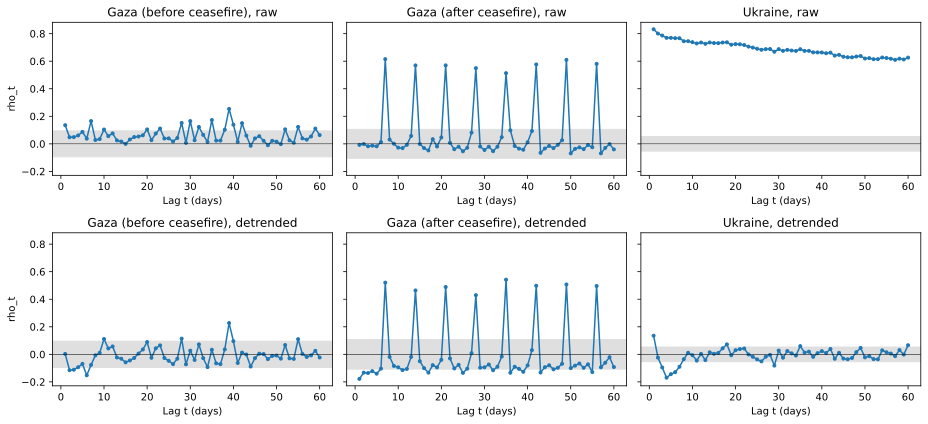

In [26]:
# Problem 3.2: rho_t = correlation of daily deaths with deaths t days later
def rho(x, max_lag=60):
    x = np.asarray(x, dtype=float)
    return np.array([np.corrcoef(x[:-t], x[t:])[0, 1] for t in range(1, max_lag + 1)])


def detrend(x, k=15):
    # subtract a centred rolling mean to remove slow changes in the level
    s = pd.Series(np.asarray(x, dtype=float))
    return (s - s.rolling(k, center=True).mean()).dropna().to_numpy()


series = {
    "Gaza (before ceasefire)": gaza_before.daily.to_numpy(),
    "Gaza (after ceasefire)": gaza[gaza.period == "after"].daily.to_numpy(),
    "Ukraine": ukraine.daily.to_numpy(),
}

fig, ax = plt.subplots(2, 3, figsize=(13, 6), sharey=True)
lags = np.arange(1, 61)
for j, (name, x) in enumerate(series.items()):
    for i, (label, y) in enumerate([("raw", x), ("detrended", detrend(x))]):
        ax[i, j].plot(lags, rho(y), "o-", markersize=3)
        band = 1.96 / np.sqrt(len(y))   # rough 95% band if there were no correlation
        ax[i, j].axhspan(-band, band, color="gray", alpha=0.25)
        ax[i, j].axhline(0, color="k", lw=0.5)
        ax[i, j].set_title(f"{name}, {label}")
        ax[i, j].set_xlabel("Lag t (days)")
ax[0, 0].set_ylabel("rho_t")
ax[1, 0].set_ylabel("rho_t")
plt.tight_layout()
plt.show()

- **Gaza before the ceasefire.** $\rho_t$ is small at almost every lag (mostly below .15 with one bump near .25 at lag 39). Days are close to independent.
- **Gaza after the ceasefire.** There are sharp spikes at $t = 7, 14, 21, \dots$ (about .5 to .6). This is a weekly reporting cycle, not a weekly cycle of deaths.
- **Ukraine, raw.** $\rho_t$ starts at about .8 and decays very slowly. The level of daily losses drifts over months, so nearby days look alike. After removing the trend, $\rho_t$ is near 0 for all lags.

So in all three series, day-to-day noise is nearly independent. Ukraine has a slowly moving level on top and Gaza has reporting rhythms on top.

### 3.3 The Ukraine data set

First a summary table. The plots after it show the series and the day-of-week pattern.

In [27]:
def summarize(x):
    x = np.asarray(x, dtype=float)
    t = np.arange(len(x))
    return {
        "days": len(x),
        "mean": x.mean(),
        "sd": x.std(ddof=1),
        "CV": cv(x),
        "variance / mean": x.var(ddof=1) / x.mean(),
        "R2 cumulative vs day": r2(t, np.cumsum(x)),
        "lag-1 rho": np.corrcoef(x[:-1], x[1:])[0, 1],
    }


pd.DataFrame({name: summarize(x) for name, x in series.items()}).round(3)

,Gaza (before ceasefire),Gaza (after ceasefire),Ukraine
days,434.000,347.000,1370.000
mean,63.806,19.331,1036.847
sd,88.431,55.851,321.787
CV,1.386,2.889,0.310
variance / mean,122.559,161.358,99.867
R2 cumulative vs day,0.964,0.859,0.991
lag-1 rho,0.135,-0.007,0.832


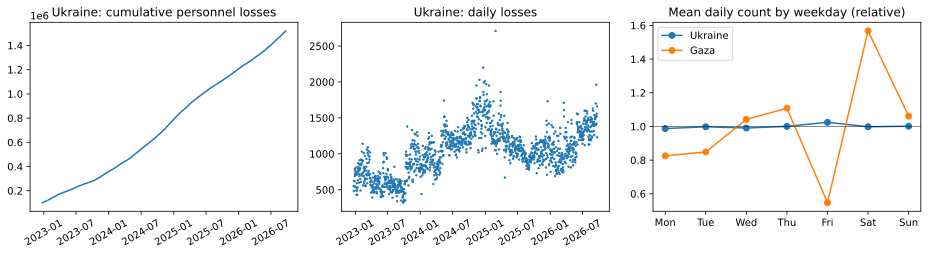

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))

ax[0].plot(ukraine.time, ukraine.counts, "-")
ax[0].set_title("Ukraine: cumulative personnel losses")
ax[0].tick_params(axis="x", rotation=30)

ax[1].plot(ukraine.time, ukraine.daily, ".", markersize=3)
ax[1].set_title("Ukraine: daily losses")
ax[1].tick_params(axis="x", rotation=30)

# Does the day of the week matter? Gaza and Ukraine side by side
u_dow = ukraine.groupby(ukraine.time.dt.dayofweek).daily.mean()
g_dow = gaza_before.groupby(gaza_before.time.dt.dayofweek).daily.mean()
ax[2].plot(u_dow.index, u_dow / u_dow.mean(), "o-", label="Ukraine")
ax[2].plot(g_dow.index, g_dow / g_dow.mean(), "o-", label="Gaza")
ax[2].axhline(1, color="k", lw=0.5)
ax[2].set_xticks(range(7))
ax[2].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax[2].set_title("Mean daily count by weekday (relative)")
ax[2].legend()

plt.tight_layout()
plt.show()

**Differences**

- Ukraine is much larger (mean about 1000 per day vs about 64) and much more regular (CV .31 vs 1.4 for Gaza before the ceasefire).
- Ukraine has a strong trend and a slow-changing level. The lag-1 $\rho$ is .83 vs .14 for Gaza.
- Ukraine has no weekday pattern. Gaza has a big Friday dip and Saturday jump, which points to reporting schedules.
- Ukraine has no ceasefire and no batching spikes at lag 7.

**Similarities**

- Both are overdispersed. The variance is 100 times the mean or more for both, where a Poisson count would have 1.
- Both have a very high cumulative $R^2$ (.96 and .99).
- Both are compiled from one side's reports and cannot be independently checked.

The last point matters for interpretation. Ukraine's windows are even more regular than Wyner's Gaza window. If low CV were proof of fabrication, the Ukraine series would be flagged more strongly. Either those numbers are also made up or the test is not specific. I can not say which from the data alone, so Ukraine is not a clean control.

## Problem 4: Reflection

The analysis changes how I see Wyner's article, but it does not settle whether the Ministry's numbers are right. Three of his statistical arguments do not hold up well. The cumulative regularity is what any count series gives. The low variation comes from one hand-picked window and it also shows up in Ukraine. The women vs children and men vs women patterns can come from reporting lags and from computing men as a leftover. Those are real problems for the claim that the numbers are "not real." But I also found that the women vs children R2 in his window is unusual (about 3% of windows), and I could not rule out that a rule-based process made some of the daily breakdowns. The honest conclusion is that this evidence is weak and cannot separate fabrication from messy reporting.

I think the data are less reliable than clean official statistics but not shown to be fake. They come from a government that is a party to the war, in a chaotic setting, with no outside audit of daily counts. Things that pull the other way are the long record of the Ministry's counts in earlier conflicts and the name-level lists that outside groups can check. A statistical test of daily regularity is not the right tool for that question. A tool built for a different question can give a confident wrong answer, and the article's tone ("the numbers are not real") went well beyond what the test can show.

On the House vote, I think statistical analysis should be part of such discussions but with care about what is claimed. Good analysis can say what the data can and cannot support, and it should be honest about forking paths and missing controls. A vote to ban a source is a political decision, and a weak test should not be used to make it look scientific. Better analysis would help. Examples: (1) compare the Ministry's daily totals with the named-ID lists and with independent estimates (capture-recapture style methods), (2) fit a model with reporting lags and ask if the lags explain the correlations, (3) check last-digit patterns and day-of-week patterns across many conflicts, and (4) compare to other conflicts with verified counts to learn what a normal CV looks like, instead of using a guess.